In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif # mutual_info_score works poorly with the continuous data
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler # for feature scaling
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# since it's a classification problem, I can't use a regression models for decision tree/random forest/ XGBoost, so I'll user the classifier models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

In [2]:
random_state = 1
df = pd.read_csv('star_classification.csv')
df.head()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


In [3]:
# unnecessary columns for the current task - identifiers or observational metadata
drop_columns = [
    'obj_ID',
    'run_ID',
    'rerun_ID',
    'cam_col',
    'field_ID',
    'spec_obj_ID',
    'plate',
    'MJD',
    'fiber_ID'
]

df = df.drop(columns=drop_columns, axis='columns')
df.head()

,alpha,delta,u,g,r,i,z,class,redshift
0,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,GALAXY,0.634794
1,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,GALAXY,0.779136
2,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,GALAXY,0.644195
3,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,GALAXY,0.932346
4,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,GALAXY,0.116123


In [4]:
df['class'].isnull().sum() # no null/blank elements

np.int64(0)

In [5]:
df.describe()

,alpha,delta,u,g,r,i,z,redshift
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,177.629117,24.135305,21.980468,20.531387,19.645762,19.084854,18.668810,0.576661
std,96.502241,19.644665,31.769291,31.750292,1.854760,1.757895,31.728152,0.730707
min,0.005528,-18.785328,-9999.000000,-9999.000000,9.822070,9.469903,-9999.000000,-0.009971
25%,127.518222,5.146771,20.352353,18.965230,18.135828,17.732285,17.460677,0.054517
50%,180.900700,23.645922,22.179135,21.099835,20.125290,19.405145,19.004595,0.424173
75%,233.895005,39.901550,23.687440,22.123767,21.044785,20.396495,19.921120,0.704154
max,359.999810,83.000519,32.781390,31.602240,29.571860,32.141470,29.383740,7.011245


In [6]:
df[df['g'] == df['g'].min()]

,alpha,delta,u,g,r,i,z,class,redshift
79543,224.006526,-0.624304,-9999.0,-9999.0,18.1656,18.01675,-9999.0,STAR,0.000089


In [7]:
df.sort_values('g').head(5) 

,alpha,delta,u,g,r,i,z,class,redshift
79543,224.006526,-0.624304,-9999.00000,-9999.00000,18.16560,18.016750,-9999.000000,STAR,0.000089
75784,239.473361,27.594369,12.10168,10.49820,10.11604,10.008650,10.441310,STAR,0.000008
4472,239.423127,28.548438,12.26240,10.51139,10.06854,13.417860,10.225510,STAR,0.000025
75620,239.207155,27.898444,12.30349,10.67180,10.19460,10.055090,10.650560,STAR,0.000003
14498,84.230172,7.138590,14.15199,10.73097,9.82207,9.469903,9.612333,STAR,0.000051


In [8]:
# there's only one row with the anomally low u, g and z values, so we'll drop it
df = df[df['g'] > -9999]

In [9]:
df['class'].value_counts(normalize=True)

class
GALAXY    0.594456
STAR      0.215932
QSO       0.189612
Name: proportion, dtype: float64

In [10]:
df.nunique() # all unique values, except the class column, which is the prediction target

alpha       99998
delta       99998
u           93747
g           92650
r           91900
i           92018
z           92006
class           3
redshift    99294
dtype: int64

In [11]:
df.dtypes # only the target value is string - no need to split the columns on categorical and numerical

alpha       float64
delta       float64
u           float64
g           float64
r           float64
i           float64
z           float64
class           str
redshift    float64
dtype: object

In [12]:
# since we only have 3 class types - STAR, GALAXY and QSO, we'll change them to 0, 1 and 2 respectively
df['class'] = df['class'].replace({'GALAXY': 0, 'STAR': 1, 'QSO': 2}).astype(int)

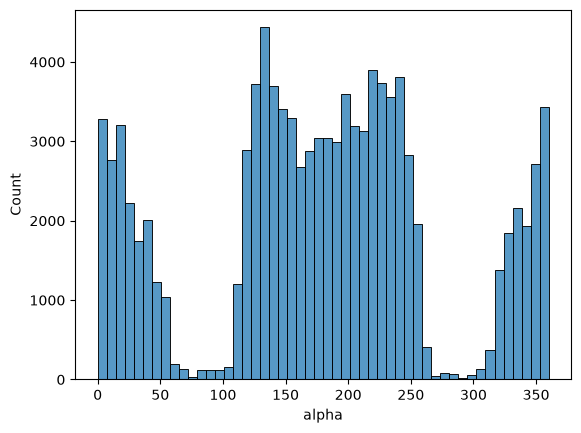

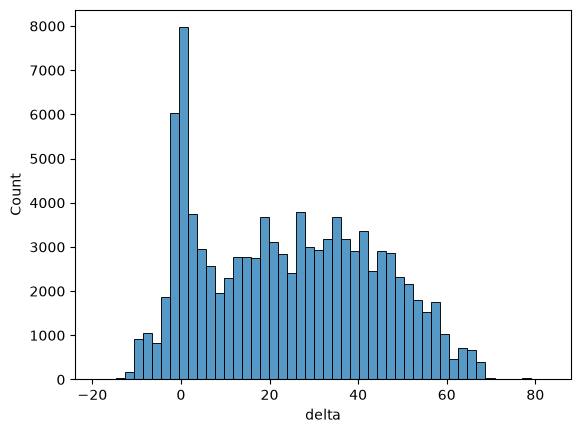

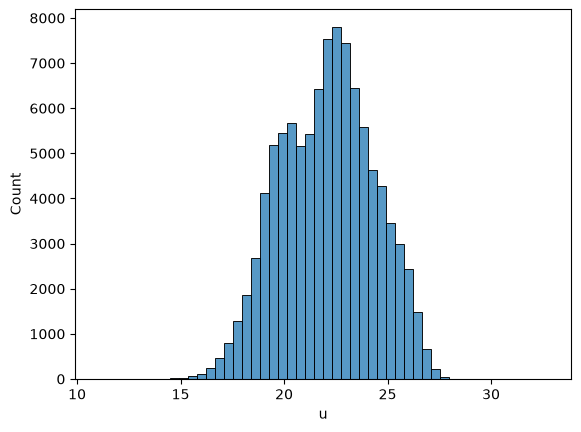

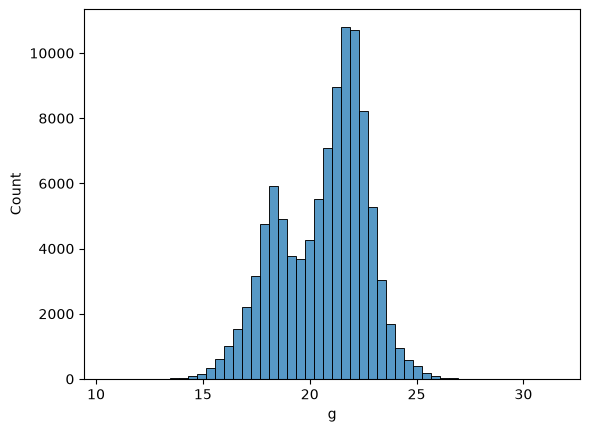

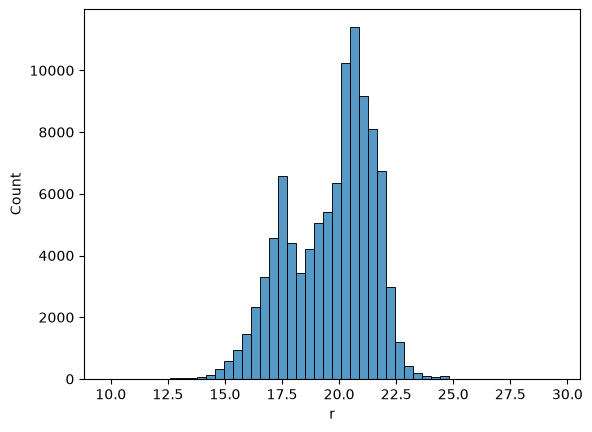

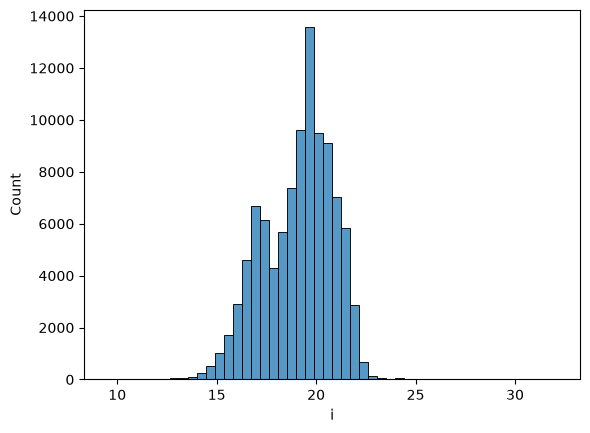

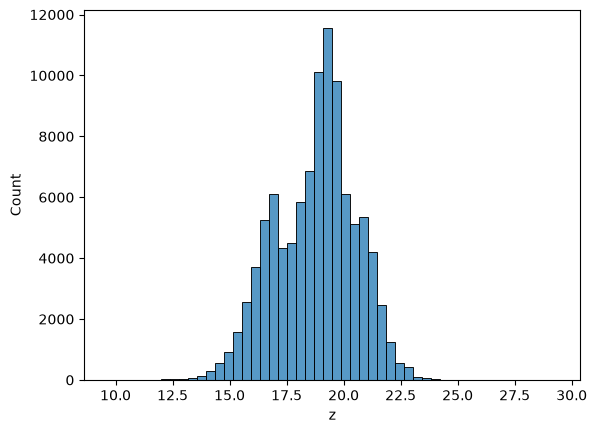

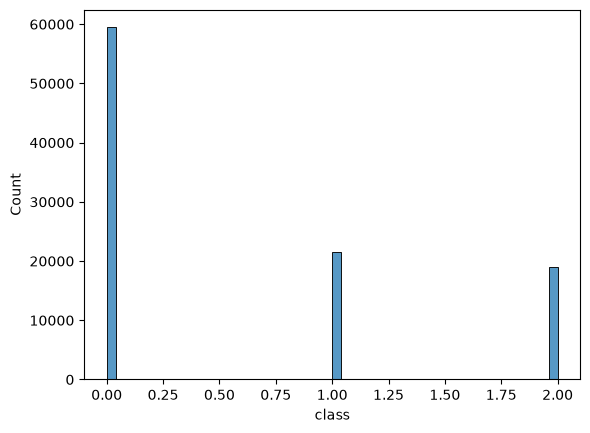

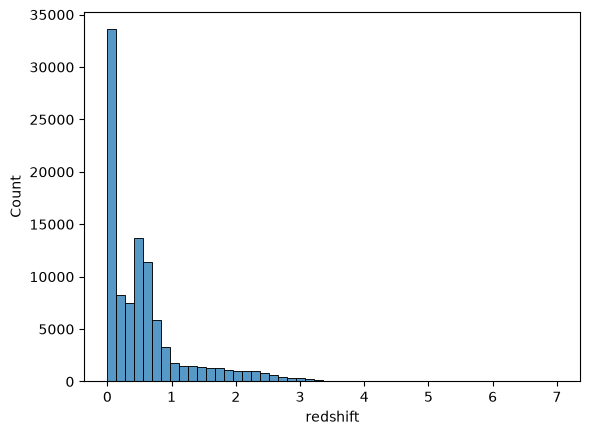

In [13]:
# looking for the data values distribution - only redshift is a little out of shape
for col in df.columns:
    sns.histplot(df[col], bins=50)
    plt.show()
# note - some features are on a different scales(0 to 350 for alpha, 0 to 3.5 for redshift), which means the need to use the Scaler

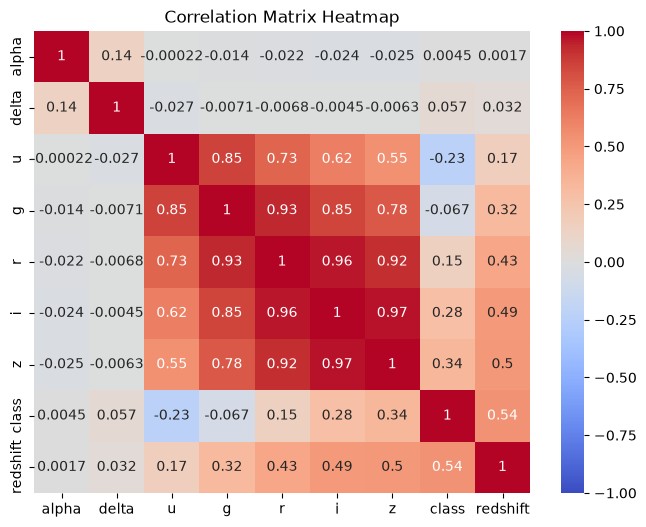

In [14]:
matrix = df.corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix Heatmap')
plt.show()
# it shows that alpha and delta has little to no correlation to other photometric parameters
# will test the models with and without alpha/delta and see if they worth keeping

In [15]:
def mutual_info(df, y):
    return mutual_info_classif (df, y)

In [16]:
def split_features_target(df, target):
    X = df.drop(columns=[target])
    y = df[target].values
    return X, y

In [17]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=random_state)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=random_state
)

dfs = [df_train, df_val, df_test, df_full_train]
dfs = [d.reset_index(drop=True) for d in dfs]
df_train, df_val, df_test, df_full_train = dfs

target = 'class'

X_train, y_train = split_features_target(df_train, target)
X_val, y_val = split_features_target(df_val, target)
X_test, y_test = split_features_target(df_test, target)
X_full_train, y_full_train = split_features_target(
    df_full_train, target
)

In [18]:
X_full_train.dtypes

alpha       float64
delta       float64
u           float64
g           float64
r           float64
i           float64
z           float64
redshift    float64
dtype: object

In [19]:
mi = mutual_info_classif(X_full_train, y_full_train)
df_info = pd.Series(mi, index=X_full_train.columns).sort_values(ascending=False).to_frame(name='Mutual Info')

df_info
# low mutual info from alpha and delta

,Mutual Info
redshift,0.801648
z,0.144059
g,0.120926
i,0.110439
u,0.100390
r,0.073556
delta,0.042999
alpha,0.040318


In [20]:
a = X_full_train.corrwith(pd.Series(y_full_train, index=df_full_train.index)).to_frame('correlation')
a.sort_values('correlation', ascending=False)
# low correlation from alpha and delta

,correlation
redshift,0.536828
z,0.340421
i,0.284306
r,0.150755
delta,0.059512
alpha,0.005629
g,-0.066534
u,-0.225803


In [21]:
# need to use the scaler, because the features are on a different value ranges(if I won't use it, the LogisticRegression will give me an error)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_full_train_scaled = scaler.transform(X_full_train)
X_test_scaled = scaler.transform(X_test)

X_val_scaled = scaler.transform(X_val)

model = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=random_state)
model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in t

In [22]:
y_pred = model.predict_proba(X_val_scaled)
y_pred_class = np.argmax(y_pred, axis=1) # getting the index of a highest probability in each row of y_pred
acc = accuracy_score(y_val, y_pred_class)
auc = roc_auc_score(y_val, y_pred, multi_class='ovr', average='macro')
print('AUC - %.3f, Accuracy - %.3f' % (auc, acc))
print(classification_report(y_val, y_pred_class))
# 95.48% prediction precision - let's test on the full_train

AUC - 0.986, Accuracy - 0.955
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     11838
           1       0.95      1.00      0.97      4289
           2       0.95      0.88      0.91      3873

    accuracy                           0.95     20000
   macro avg       0.95      0.95      0.95     20000
weighted avg       0.95      0.95      0.95     20000



In [23]:
model.fit(X_full_train_scaled, y_full_train)
y_pred = model.predict_proba(X_test_scaled)
y_pred_class = np.argmax(y_pred, axis=1)
acc = accuracy_score(y_test, y_pred_class)
auc = roc_auc_score(y_test, y_pred, multi_class='ovr', average='macro')
print('AUC - %.3f, Accuracy - %.3f' % (auc, acc))
print(classification_report(y_test, y_pred_class))
# 95.83%

AUC - 0.988, Accuracy - 0.958
              precision    recall  f1-score   support

           0       0.96      0.97      0.97     11836
           1       0.95      1.00      0.97      4369
           2       0.95      0.89      0.92      3795

    accuracy                           0.96     20000
   macro avg       0.95      0.95      0.95     20000
weighted avg       0.96      0.96      0.96     20000



In [24]:
columns = [c for c in df.columns if c not in ['alpha', 'delta', 'class']]

In [25]:
X_train_scaled = scaler.fit_transform(X_train[columns])
X_full_train_scaled = scaler.transform(X_full_train[columns])
X_test_scaled = scaler.transform(X_test[columns])
X_val_scaled = scaler.transform(X_val[columns])

model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in t

In [26]:
y_pred = model.predict_proba(X_val_scaled)
y_pred_class = np.argmax(y_pred, axis=1)
acc = accuracy_score(y_val, y_pred_class)
auc = roc_auc_score(y_val, y_pred, multi_class='ovr', average='macro')
print('AUC - %.3f, Accuracy - %.3f' % (auc, acc))
print(classification_report(y_val, y_pred_class))

# 95.32%

AUC - 0.986, Accuracy - 0.953
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     11838
           1       0.95      1.00      0.97      4289
           2       0.94      0.87      0.91      3873

    accuracy                           0.95     20000
   macro avg       0.95      0.95      0.95     20000
weighted avg       0.95      0.95      0.95     20000



In [27]:
model.fit(X_full_train_scaled, y_full_train)
y_pred = model.predict_proba(X_test_scaled)
y_pred_class = np.argmax(y_pred, axis=1)
acc = accuracy_score(y_test, y_pred_class)
auc = roc_auc_score(y_test, y_pred, multi_class='ovr', average='macro')
print('AUC - %.3f, Accuracy - %.3f' % (auc, acc))
print(classification_report(y_test, y_pred_class))
# 95.79% - difference of 0.04% from the predictions with the alpha/delta in them
# It shows that alpha/delta has a negligible influence on the prediction overall - predictions seems better with the alpha/delta, we'll keep them

AUC - 0.988, Accuracy - 0.958
              precision    recall  f1-score   support

           0       0.96      0.97      0.96     11836
           1       0.95      1.00      0.97      4369
           2       0.95      0.88      0.92      3795

    accuracy                           0.96     20000
   macro avg       0.95      0.95      0.95     20000
weighted avg       0.96      0.96      0.96     20000



In [28]:
# Desicion Tree and Random Forest

In [29]:
# first we'll find the best max_depth
# since my dataset contains a lot of data, the tree has plenty of samples to split from, so I won't be testing the min_samples_leaf value

In [30]:
for depth in [3, 5, 10, 15, 20, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=random_state)
    model.fit(X_train, y_train)
    
    y_pred = model.predict_proba(X_val)
    y_pred_class = np.argmax(y_pred, axis=1)

    acc = accuracy_score(y_val, y_pred_class)
    auc = roc_auc_score(y_val, y_pred, multi_class='ovr', average='macro')

    print('Depth - %4s, AUC - %.3f, Accuracy - %.3f' % (depth, auc, acc))
# the depth of 10 looks like the best choise

Depth -    3, AUC - 0.972, Accuracy - 0.949
Depth -    5, AUC - 0.984, Accuracy - 0.963
Depth -   10, AUC - 0.985, Accuracy - 0.971
Depth -   15, AUC - 0.967, Accuracy - 0.966
Depth -   20, AUC - 0.968, Accuracy - 0.964
Depth - None, AUC - 0.966, Accuracy - 0.962


In [31]:
max_depth = 10

In [32]:
# now we'll test on the full_train
model = DecisionTreeClassifier(max_depth=max_depth, random_state=random_state)
model.fit(X_full_train, y_full_train)

y_pred = model.predict_proba(X_test)
y_pred_class = np.argmax(y_pred, axis=1)

acc = accuracy_score(y_test, y_pred_class)
auc = roc_auc_score(y_test, y_pred, multi_class='ovr', average='macro')

print('AUC - %.3f, Accuracy - %.3f' % (auc, acc))

AUC - 0.987, Accuracy - 0.974


In [33]:
# Now we'll test the RandomForest with different values of n_estimators
best_acc = 0
best_est = 0

for n in range(10, 201, 10):
    model = RandomForestClassifier(n_estimators=n, max_depth=max_depth, random_state=random_state)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)
    y_pred_class = np.argmax(y_pred, axis=1)

    acc = accuracy_score(y_val, y_pred_class)
    auc = roc_auc_score(y_val, y_pred, multi_class='ovr', average='macro')

    if(acc>best_acc):
        best_acc=acc
        best_est = n
        
    print('Estimators - %4s, AUC - %.3f, Accuracy - %.3f' % (n, auc, acc))

print('Best N - %.3f' % (best_est))

# best n_estimators is 90, so we'll use it

Estimators -   10, AUC - 0.992, Accuracy - 0.973
Estimators -   20, AUC - 0.993, Accuracy - 0.973
Estimators -   30, AUC - 0.993, Accuracy - 0.973
Estimators -   40, AUC - 0.993, Accuracy - 0.973
Estimators -   50, AUC - 0.993, Accuracy - 0.973
Estimators -   60, AUC - 0.993, Accuracy - 0.974
Estimators -   70, AUC - 0.993, Accuracy - 0.973
Estimators -   80, AUC - 0.993, Accuracy - 0.973
Estimators -   90, AUC - 0.993, Accuracy - 0.974
Estimators -  100, AUC - 0.993, Accuracy - 0.973
Estimators -  110, AUC - 0.993, Accuracy - 0.973
Estimators -  120, AUC - 0.993, Accuracy - 0.973
Estimators -  130, AUC - 0.993, Accuracy - 0.973
Estimators -  140, AUC - 0.993, Accuracy - 0.973
Estimators -  150, AUC - 0.993, Accuracy - 0.973
Estimators -  160, AUC - 0.993, Accuracy - 0.973
Estimators -  170, AUC - 0.993, Accuracy - 0.973
Estimators -  180, AUC - 0.993, Accuracy - 0.973
Estimators -  190, AUC - 0.993, Accuracy - 0.973
Estimators -  200, AUC - 0.993, Accuracy - 0.973
Best N - 90.000


In [34]:
n_estimators = 90

In [35]:
model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=1)
model.fit(X_full_train, y_full_train)

y_pred = model.predict_proba(X_test)
y_pred_class = np.argmax(y_pred, axis=1)

acc = accuracy_score(y_test, y_pred_class)
auc = roc_auc_score(y_test, y_pred, multi_class='ovr', average='macro')

print('AUC - %.3f, Accuracy - %.3f' % (auc, acc))

AUC - 0.995, Accuracy - 0.976


In [36]:
# now we'll test the XGBoost model

features = list(X_train.columns)

dtrain = xgb.DMatrix(
    X_train,
    label=y_train,
    feature_names=features
)

dfulltrain =  xgb.DMatrix(
    X_full_train,
    label=y_full_train,
    feature_names=features
)

dval = xgb.DMatrix(
    X_val,
    label=y_val,
    feature_names=features
)

dtest = xgb.DMatrix(
    X_test,
    label=y_test,
    feature_names=features
)

In [37]:
# first, we'll need to find the best values for eta, max_depth and min_child_weight

best_acc = 0
best_params = {}

for eta in [0.1, 0.3, 0.5]:
    for depth in [3, 5, 6, 10]:
        for mcw in [1, 5, 10]:
            xgb_params = {
                'eta': eta,
                'max_depth': depth,
                'min_child_weight': mcw,
                
                'objective': 'multi:softprob', # for the multi-class problest
                'eval_metric': 'mlogloss',     # AUC and RMCE not working for non-binary models :(
                'num_class': 3,                # since we have 3 classes to predict, the number is 3
                
                'seed': 1,
                'verbosity': 0,
            }

            model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                              evals=[(dval, 'validation')],
                              early_stopping_rounds=10,
                              verbose_eval=False)

            y_pred = model.predict(dval)
            y_pred_class = np.argmax(y_pred, axis=1)
            acc = accuracy_score(y_val, y_pred_class)
            auc = roc_auc_score(y_val, y_pred, multi_class='ovr', average='macro')

            if acc > best_acc:
                best_acc = acc
                best_params = xgb_params

            print('ETA - %s, Depth - %s, Min child weight - %s, AUC - %.3f, Accuracy  - %.3f' % (eta, depth, mcw, auc, acc))

print('Best accuracy: %.3f' % best_acc)
print('Best params:', best_params)
# the best parameters are: eta=0.1, max_depth=6, min_child_weight=5, so we'll use them on full train data

ETA - 0.1, Depth - 3, Min child weight - 1, AUC - 0.994, Accuracy  - 0.970
ETA - 0.1, Depth - 3, Min child weight - 5, AUC - 0.994, Accuracy  - 0.970
ETA - 0.1, Depth - 3, Min child weight - 10, AUC - 0.994, Accuracy  - 0.970
ETA - 0.1, Depth - 5, Min child weight - 1, AUC - 0.994, Accuracy  - 0.972
ETA - 0.1, Depth - 5, Min child weight - 5, AUC - 0.994, Accuracy  - 0.973
ETA - 0.1, Depth - 5, Min child weight - 10, AUC - 0.994, Accuracy  - 0.972
ETA - 0.1, Depth - 6, Min child weight - 1, AUC - 0.994, Accuracy  - 0.973
ETA - 0.1, Depth - 6, Min child weight - 5, AUC - 0.994, Accuracy  - 0.973
ETA - 0.1, Depth - 6, Min child weight - 10, AUC - 0.994, Accuracy  - 0.973
ETA - 0.1, Depth - 10, Min child weight - 1, AUC - 0.994, Accuracy  - 0.973
ETA - 0.1, Depth - 10, Min child weight - 5, AUC - 0.995, Accuracy  - 0.973
ETA - 0.1, Depth - 10, Min child weight - 10, AUC - 0.995, Accuracy  - 0.973
ETA - 0.3, Depth - 3, Min child weight - 1, AUC - 0.994, Accuracy  - 0.973
ETA - 0.3, Depth -

In [38]:
%%capture output
xgb_params = {
    'eta': 0.1,
    'max_depth': 6,
    'min_child_weight': 5,
    
    'objective': 'multi:softprob',
    'eval_metric': 'mlogloss',
    'num_class': 3,
    
    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dfulltrain, num_boost_round=100, evals = [(dfulltrain, 'train'), (dtest, 'test')])

In [39]:
y_pred = model.predict(dtest)
y_pred_class = np.argmax(y_pred, axis=1)
acc = accuracy_score(y_test, y_pred_class)
auc = roc_auc_score(y_test, y_pred, multi_class='ovr', average='macro')

print('AUC - %.3f, Accuracy - %.3f' % (auc, acc))

AUC - 0.996, Accuracy - 0.976


In [40]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.split('\n')[0:-1]:
        it_line, train_line, val_line = line.split('\t')
        it = int(it_line.strip("[]"))
        train = float(train_line.split(":")[1])
        val = float(val_line.split(":")[1])
        results.append((it, train, val))
    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [41]:
df_scores = parse_xgb_output(output)

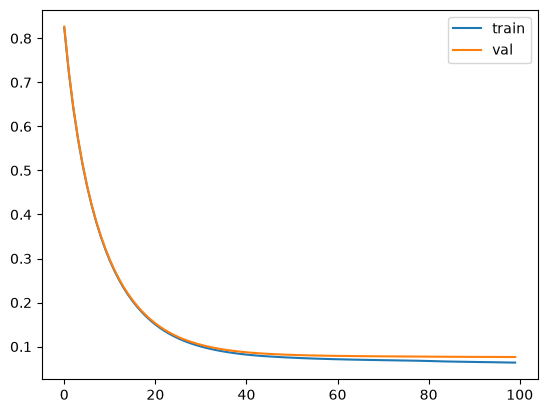

In [42]:
plt.plot(df_scores.num_iter, df_scores.train_auc, label = "train")
plt.plot(df_scores.num_iter, df_scores.val_auc, label = "val")
plt.legend()

# since it's showing mgloss and not accuracy, the lover the value - the better

In [43]:
# in the end, we got:
# Logistic regression: Accuracy score -  0.958, ROC AUC score -  0.988
# Decision tree: AUC - 0.987, Accuracy - 0.974
# Random forest: AUC - 0.994, Accuracy - 0.974
# XGBoost: AUC - 0.996, Accuracy - 0.976

# XGBoost is the best choise(even if by a small amount of 0.002, or 0.2%, of AUC score), so we'll use it as our model